<a href="https://colab.research.google.com/github/julianaabushkara/EMusA-AI-Museum/blob/main/Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Museum stand - interaction analysis

Everything in one notebook: **hold time per object, AI latency, questions & answers per visitor**.
Each section has a short explanation of what it does, then the table (pandas) and graph right under it.

**How to use (Google Colab)**
1. Keep this notebook in the `JSON` folder in Google Drive, next to `CODE.py`, `CLOCK` and `NO_CLOCK`.
2. Open it with **Google Colaboratory** and run it from top to bottom (**Runtime → Run all**).
3. When asked, allow access to Google Drive. If the folder is not found, set `ROOT` in the Setup cell (see the note there).

**Sections**
1. Setup
2. Load the logs, split into visitors, remove duplicates (with an audit table)
3. Build the tables
4. Overall summary
5. Which object is held - and for how long
6. Per visitor
7. First object touched
8. Questions asked
9. AI latency (pipeline timing)
10. Languages
11. **Every question & answer per visitor, with timings**
12. Export to Excel / CSV

## 1. Setup
Mount Google Drive, point to the `JSON` folder, and import `CODE.py` from it.
`CODE.py` (the analysis script) is imported and reused, so the numbers here are exactly the same as when you run `CODE.py`.

**If the folder is not found:** the `JSON` folder is shared with you, so it must be reachable from *My Drive*. In Drive, right-click the shared folder → **Organize → Add shortcut** → put it in My Drive. Then set `ROOT` below to that location (the cell also tries to find the folder by itself and prints the path).

In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# --- Mount Google Drive ------------------------------------------------------
from google.colab import drive
drive.mount('/content/drive')

# Folder that contains CODE.py, CLOCK and NO_CLOCK (edit if the folder is elsewhere)
ROOT = Path('/content/drive/MyDrive/ניתוח דאטא מפגשים/JSON')

# If that path is wrong, look for a folder named JSON that holds CODE.py (a few levels deep)
if not (ROOT / 'CODE.py').exists():
    found = None
    base = Path('/content/drive/MyDrive')
    for depth in range(1, 5):
        for p in base.glob('/'.join(['*'] * depth) + '/CODE.py'):
            if p.parent.name == 'JSON' and (p.parent / 'CLOCK').exists():
                found = p.parent
                break
        if found:
            break
    if found is None:
        raise FileNotFoundError('Could not find the JSON folder with CODE.py. '
                                'Add a shortcut to it in My Drive and set ROOT above.')
    ROOT = found
    print('Found the folder automatically. To skip the search next time, set:')
    print(f"ROOT = Path('{ROOT}')\n")

sys.path.insert(0, str(ROOT))
import CODE as C                      # the helper functions (session splitting, hold times, ...)

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 220)
plt.rcParams["figure.dpi"] = 110

AI_COLOR, NOAI_COLOR = "#2a7de1", "#9aa5b1"
COLORS = ["#2a7de1", "#f2a33a", "#8fbf5a", "#c0504d", "#8064a2", "#999999"]
print("Folder:", ROOT)
print("Sub-folders:", [p.name for p in ROOT.iterdir() if p.is_dir()])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder: /content/drive/MyDrive/ניתוח דאטא מפגשים/JSON
Sub-folders: ['NO_CLOCK', 'analysis_out', '__pycache__', 'CLOCK']


## 2. Load the logs, split into visitors, remove duplicates
**What happens here**
- Every `.jsonl` file in every sub-folder is read (repeated file names like `interaction_log (3)` in both folders are fine).
- A log file can hold **several visitors**. A new visitor (session) starts at every `enter` event, or after 30 minutes of silence.
- Two `enter` events within 3 minutes = the sensor fired twice -> same visitor (merged).
- Sessions with no pick-up and no question are dropped (**empty**). Chats with no `enter` and no pick-up are dropped (**test chats**).
- The server log is cumulative, so the same visitor can appear again in a later download. Sessions that share >= 80% of their events with another session are **duplicates**: counted once, the longest copy is kept.

The table below lists **every session found** and what happened to it.

In [ ]:
kept, audit, stats = C.collect_sessions(ROOT, exclude_dirs=(ROOT / "analysis_out", ROOT / "qa_out", ROOT / "graphs"))
audit_df = pd.DataFrame(audit)

summary = pd.Series({
    "files read": stats["files"],
    "sessions found in the files": stats["raw_sessions"],
    "dropped: empty": stats["empty"],
    "dropped: test chats (no enter / no pick-up)": stats["test_chat_no_enter_no_pickup"],
    "dropped: duplicates": stats["duplicate"],
    "enter-events merged into one visitor": stats["merged_reenter"],
    "VISITORS (unique sessions kept)": len(kept),
}, name="count").to_frame()
display(summary)

,count
files read,25
sessions found in the files,29
dropped: empty,3
dropped: test chats (no enter / no pick-up),1
dropped: duplicates,0
enter-events merged into one visitor,2
VISITORS (unique sessions kept),25


In [ ]:
# what happened to every session
display(audit_df.sort_values(["status", "start"]).reset_index(drop=True))

,folder,file,session_in_file,start,end,n_events,n_pickups,n_questions,has_enter_event,status,user_no,duplicate_of,note
0,NO_CLOCK,interaction_log (10).jsonl,1,2026-07-07T13:46:54+03:00,2026-07-07T13:46:54+03:00,1,0,0,True,empty,,,
1,CLOCK,interaction_log (12).jsonl,1,2026-10-17T09:02:08+03:00,2026-10-17T09:13:11+03:00,43,0,0,True,empty,,,
2,CLOCK,interaction_log (17).jsonl,1,2026-10-31T09:10:27+02:00,2026-10-31T09:10:27+02:00,1,0,0,True,empty,,,
3,NO_CLOCK,interaction_log (3).jsonl,1,2026-05-06T16:16:33+03:00,2026-05-06T16:23:58+03:00,12,2,9,True,kept,1,,
4,NO_CLOCK,interaction_log (6).jsonl,1,2026-06-23T13:27:59+03:00,2026-06-23T13:40:38+03:00,18,6,5,True,kept,2,,
5,NO_CLOCK,interaction_log (4).jsonl,1,2026-06-23T14:02:12+03:00,2026-06-23T14:17:56+03:00,20,9,2,True,kept,3,,
6,NO_CLOCK,interaction_log (7).jsonl,1,2026-06-23T14:34:31+03:00,2026-06-23T14:48:20+03:00,15,3,8,True,kept,4,,
7,NO_CLOCK,interaction_log (8).jsonl,1,2026-07-04T13:08:47+03:00,2026-07-04T13:21:32+03:00,13,4,4,True,kept,5,,
8,NO_CLOCK,interaction_log (10).jsonl,2,2026-07-07T13:55:06+03:00,2026-07-07T14:11:56+03:00,20,7,6,True,kept,6,,
9,NO_CLOCK,interaction_log (9).jsonl,1,2026-07-07T14:41:42+03:00,2026-07-07T14:59:58+03:00,20,7,5,True,kept,7,,


In [ ]:
# the duplicates that were removed, and which session they were a copy of
display(audit_df[audit_df.status == "duplicate"][["folder", "file", "session_in_file", "start", "n_questions", "duplicate_of"]])

,folder,file,session_in_file,start,n_questions,duplicate_of


## 3. Build the tables
For every kept visitor the notebook computes:
- **persons** - one row per visitor (session length, hold time per object, number of questions, AI timing, ...)
- **holds** - one row per pick-up (object, start, end, seconds). Pick-ups shorter than 3 seconds are sensor flicker and are left out of the statistics.
- **utts** - one row per question the visitor asked: the question, the AI answer, the object held, and the pipeline timings when they were logged.

A pick-up is counted from the `lift` event until the object is put back (`none`) or another object is lifted.

In [ ]:
rows, hl, ul = [], [], []
for s in kept:
    r, h, u = C.analyze_session(s["events"], s["person"], s["folder"], s["has_enter"], s["user_no"])
    rows.append(r); hl += h; ul += u

persons = pd.DataFrame(rows)
holds_all = pd.DataFrame(hl)
utts = pd.DataFrame(ul)
utts["ts"] = pd.to_datetime(utts["ts"], utc=True).dt.tz_convert("Asia/Jerusalem")
persons["date"] = pd.to_datetime(persons["date"])
holds = holds_all[~holds_all["noise"]].copy()          # valid pick-ups only

info = {"files_read": stats["files"], "sessions_found": stats["raw_sessions"],
        "sessions_empty_dropped": stats["empty"], "sessions_test_chat_dropped": stats["test_chat_no_enter_no_pickup"],
        "sessions_duplicate_dropped": stats["duplicate"], "reenters_merged": stats["merged_reenter"],
        "bad_json_lines": stats["bad_lines"]}
overall, items, latency = C.summarize(rows, hl, ul, info)
items = pd.DataFrame(items); latency = pd.DataFrame(latency); overall = pd.DataFrame(overall)

print(f"{len(persons)} visitors | {len(holds)} valid pick-ups ({len(holds_all) - len(holds)} flicker pick-ups ignored) | {len(utts)} questions")
display(persons.head())

25 visitors | 107 valid pick-ups (26 flicker pick-ups ignored) | 110 questions


,user_no,folder,person,date,start_time,has_enter_event,session_sec,multi_item_events,n_pickups,noise_pickups_ignored,duplicate_lifts_ignored,unclosed_holds,hold_total_sec,hold_pct_of_session,hold_avg_per_pickup_sec,hold_ai_items_sec,hold_non_ai_items_sec,hold_0_Kohl_Vessel_sec,hold_1_Hidden_artifact_1_sec,hold_2_Hidden_artifact_2_sec,hold_3_Nike_Figurine_sec,items_touched,n_questions,questions_without_object,timing_measured,n_timed_questions,ai_total_avg_sec,ai_total_median_sec,ai_total_max_sec,stt_avg_sec,gpt_avg_sec,lang_avg_sec,tts_avg_sec,suspect_misheard,suspect_misheard_pct,very_short,hallucination_phrase,other_language,ai_asked_to_repeat,main_language,languages_used
0,1,NO_CLOCK,NO_CLOCK/interaction_log (3)#s1,2026-05-06,16:16:33,True,445.0,0,2,0,0,1,359.0,80.7,179.5,359.0,0.0,136.0,0.0,0.0,223.0,2,9,0,False,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,22.2,0,1,0,1,Arabic,Arabic:9
1,2,NO_CLOCK,NO_CLOCK/interaction_log (6)#s1,2026-06-23,13:27:59,True,759.0,0,5,0,1,0,590.0,77.7,118.0,377.0,213.0,331.0,213.0,0.0,46.0,3,5,0,False,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,40.0,0,0,2,0,Arabic,"Arabic:3,Korean:1,Latin:1"
2,3,NO_CLOCK,NO_CLOCK/interaction_log (4)#s1,2026-06-23,14:02:12,True,944.0,0,6,2,1,0,680.0,72.0,113.3,282.0,398.0,120.0,193.0,205.0,162.0,4,2,0,False,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,50.0,0,0,1,0,Arabic,"Arabic:1,Latin:1"
3,4,NO_CLOCK,NO_CLOCK/interaction_log (7)#s1,2026-06-23,14:34:31,True,829.0,0,3,0,0,0,678.0,81.8,226.0,385.0,293.0,190.0,293.0,0.0,195.0,3,8,0,False,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,50.0,1,1,3,0,Latin,"Latin:5,Arabic:3"
4,5,NO_CLOCK,NO_CLOCK/interaction_log (8)#s1,2026-07-04,13:08:47,True,765.0,0,4,0,0,0,616.0,80.5,154.0,345.0,271.0,141.0,187.0,84.0,204.0,4,4,0,False,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0.0,0,0,0,0,Arabic,Arabic:4


## 4. Overall summary
One row with the main numbers over all visitors: average time holding objects, share of the session spent holding, number of questions, how many questions have pipeline timing, and so on.

In [ ]:
display(overall.T.rename(columns={0: "value"}))

,value
files_read,25.00
sessions_found,29.00
sessions_empty_dropped,3.00
sessions_test_chat_dropped,1.00
sessions_duplicate_dropped,0.00
reenters_merged,2.00
bad_json_lines,0.00
n_people,25.00
n_people_with_timing,16.00
avg_session_sec,765.24


## 5. Which object is held - and for how long
**Table (per object):** number of pick-ups, how many visitors touched it, total / average / median / longest hold time, and how many questions were asked while holding it.

**Graph:** left - average seconds per pick-up (dot = median, `n` = pick-ups); middle - % of visitors who touched the object; right - total minutes the object was held by everybody.
Blue = AI-enabled object, grey = no AI.

In [ ]:
display(items)

,item,item_name,ai_enabled,n_pickups,n_people_touched,pct_people_touched,total_hold_sec,avg_per_pickup_sec,median_per_pickup_sec,max_pickup_sec,avg_per_person_who_touched_sec,avg_per_person_all_sec,n_questions_asked
0,0,Kohl Vessel,True,31,21,84.0,3398.0,109.61,103.0,241.0,161.81,135.9,52
1,1,Hidden artifact 1,False,26,19,76.0,4842.0,186.23,188.0,596.0,254.84,193.7,0
2,2,Hidden artifact 2,False,15,11,44.0,1656.0,110.40,88.0,266.0,150.55,66.2,0
3,3,Nike Figurine,True,35,21,84.0,3668.0,104.80,67.0,507.0,174.67,146.7,52


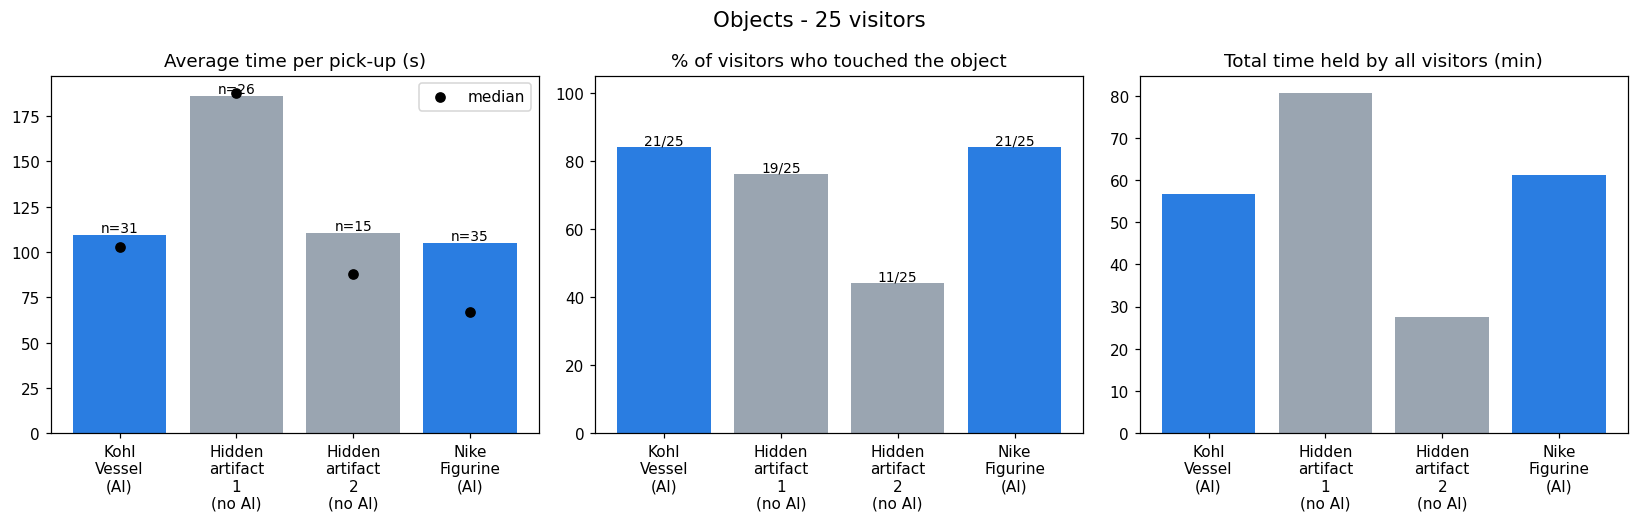

In [ ]:
n_vis = len(persons)
lab = [f"{n.replace(' ', chr(10))}\n({'AI' if a else 'no AI'})" for n, a in zip(items.item_name, items.ai_enabled)]
col = [AI_COLOR if a else NOAI_COLOR for a in items.ai_enabled]

fig, ax = plt.subplots(1, 3, figsize=(15, 4.8))
ax[0].bar(lab, items.avg_per_pickup_sec.fillna(0), color=col)
ax[0].scatter(lab, items.median_per_pickup_sec.fillna(0), color="black", zorder=3, label="median")
for i, r in items.iterrows():
    ax[0].text(i, r.avg_per_pickup_sec or 0, f"n={r.n_pickups}", ha="center", va="bottom", fontsize=9)
ax[0].set_title("Average time per pick-up (s)"); ax[0].legend()

ax[1].bar(lab, items.pct_people_touched.fillna(0), color=col)
for i, r in items.iterrows():
    ax[1].text(i, r.pct_people_touched or 0, f"{r.n_people_touched}/{n_vis}", ha="center", va="bottom", fontsize=9)
ax[1].set_ylim(0, 105); ax[1].set_title("% of visitors who touched the object")

ax[2].bar(lab, items.total_hold_sec / 60, color=col)
ax[2].set_title("Total time held by all visitors (min)")
fig.suptitle(f"Objects - {n_vis} visitors", fontsize=14)
plt.tight_layout(); plt.show()

### How long is one pick-up?
**Table:** distribution of the pick-up duration (seconds) per object (count, mean, quartiles, max).
**Graph:** left - histogram of all pick-ups (AI vs no-AI objects); right - box plot per object (the box is the middle 50% of pick-ups).

In [ ]:
display(holds.groupby("item_name")["hold_sec"].describe().round(1))

,count,mean,std,min,25%,50%,75%,max
item_name,,,,,,,,
Hidden artifact 1,26.0,186.2,135.5,3.0,105.8,188.0,280.8,596.0
Hidden artifact 2,15.0,110.4,79.3,3.0,66.0,88.0,170.5,266.0
Kohl Vessel,31.0,109.6,75.4,4.0,45.5,103.0,167.5,241.0
Nike Figurine,35.0,104.8,105.2,3.0,24.5,67.0,168.0,507.0


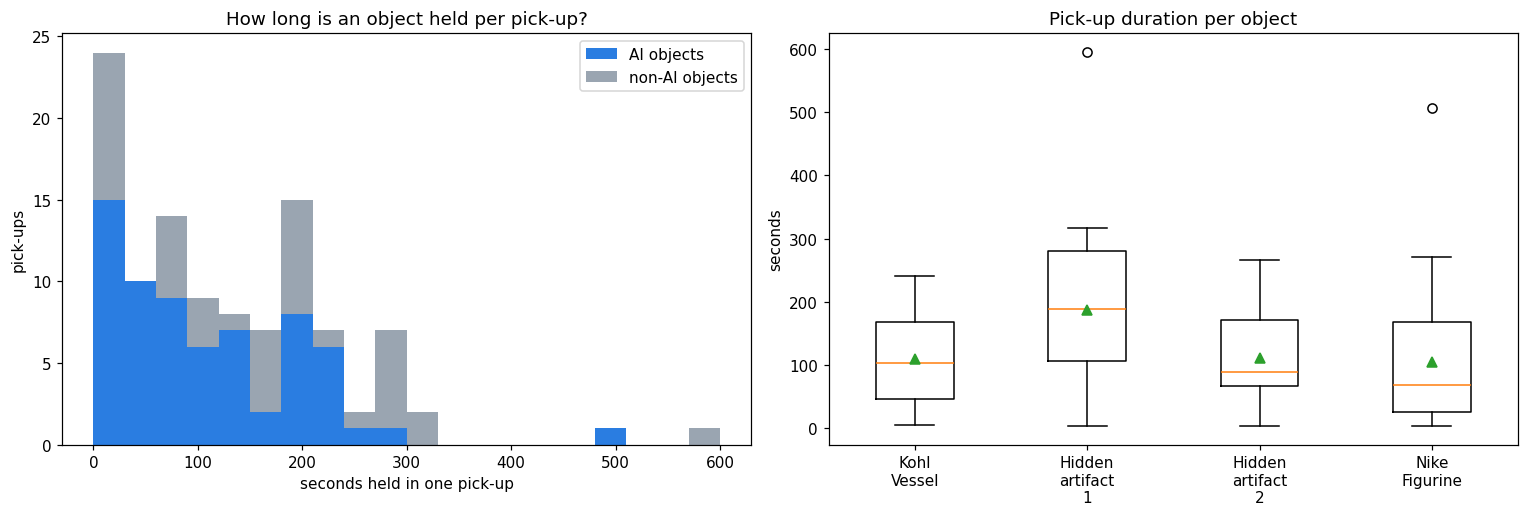

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ai = holds[holds.ai_enabled == True].hold_sec
nai = holds[holds.ai_enabled != True].hold_sec
bins = np.arange(0, min(holds.hold_sec.max(), 600) + 30, 30)
ax[0].hist([ai, nai], bins=bins, stacked=True, color=[AI_COLOR, NOAI_COLOR], label=["AI objects", "non-AI objects"])
ax[0].set_xlabel("seconds held in one pick-up"); ax[0].set_ylabel("pick-ups"); ax[0].legend()
ax[0].set_title("How long is an object held per pick-up?")

order = list(items.item_name)
data = [holds[holds.item_name == n].hold_sec for n in order]
ax[1].boxplot(data, tick_labels=[n.replace(" ", "\n") for n in order], showmeans=True)
ax[1].set_ylabel("seconds"); ax[1].set_title("Pick-up duration per object")
plt.tight_layout(); plt.show()

## 6. Per visitor
**Table:** seconds each visitor spent holding each object (rows = visitors U1, U2, ...; the last columns add the total, the session length and the % of the session spent holding).

**Graphs:** (1) stacked bars - minutes holding each object per visitor; (2) session length vs time actually holding objects.

In [ ]:
per_user = holds.pivot_table(index="user_no", columns="item_name", values="hold_sec", aggfunc="sum", fill_value=0)
per_user = per_user.reindex(persons.user_no).fillna(0)
per_user = per_user[[n for n in items.item_name if n in per_user.columns]]
per_user["TOTAL holding (s)"] = per_user.sum(axis=1)
per_user.insert(0, "date", persons.set_index("user_no").date.dt.date)
per_user["session (s)"] = persons.set_index("user_no").session_sec
per_user["% of session holding"] = (100 * per_user["TOTAL holding (s)"] / per_user["session (s)"]).round(1)
per_user["pick-ups"] = persons.set_index("user_no").n_pickups
per_user["questions"] = persons.set_index("user_no").n_questions
per_user.index = "U" + per_user.index.astype(str)
display(per_user.round(0))

item_name,date,Kohl Vessel,Hidden artifact 1,Hidden artifact 2,Nike Figurine,TOTAL holding (s),session (s),% of session holding,pick-ups,questions
user_no,,,,,,,,,,
U1,2026-05-06,136.0,0.0,0.0,223.0,359.0,445.0,81.0,2,9
U2,2026-06-23,331.0,213.0,0.0,46.0,590.0,759.0,78.0,5,5
U3,2026-06-23,120.0,193.0,205.0,162.0,680.0,944.0,72.0,6,2
U4,2026-06-23,190.0,293.0,0.0,195.0,678.0,829.0,82.0,3,8
U5,2026-07-04,141.0,187.0,84.0,204.0,616.0,765.0,80.0,4,4
U6,2026-07-07,85.0,280.0,175.0,288.0,828.0,1010.0,82.0,6,6
U7,2026-07-07,239.0,288.0,190.0,136.0,853.0,1096.0,78.0,4,5
U8,2026-07-07,293.0,312.0,184.0,182.0,971.0,1158.0,84.0,7,10
U9,2026-08-01,0.0,178.0,0.0,118.0,296.0,529.0,56.0,4,3


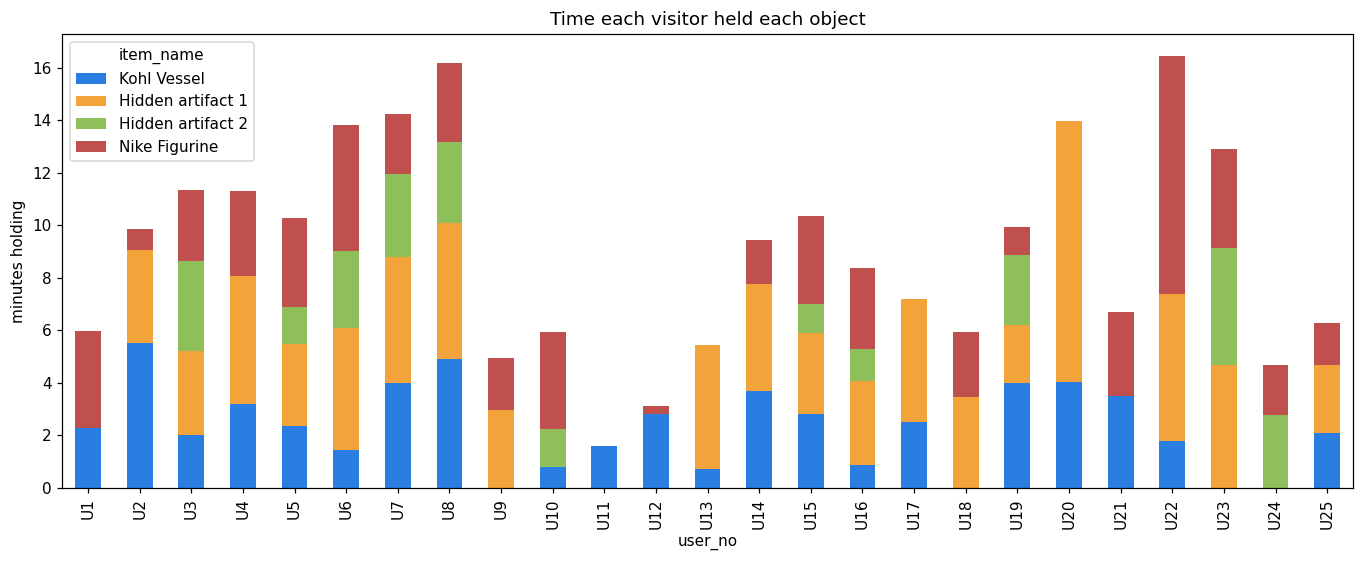

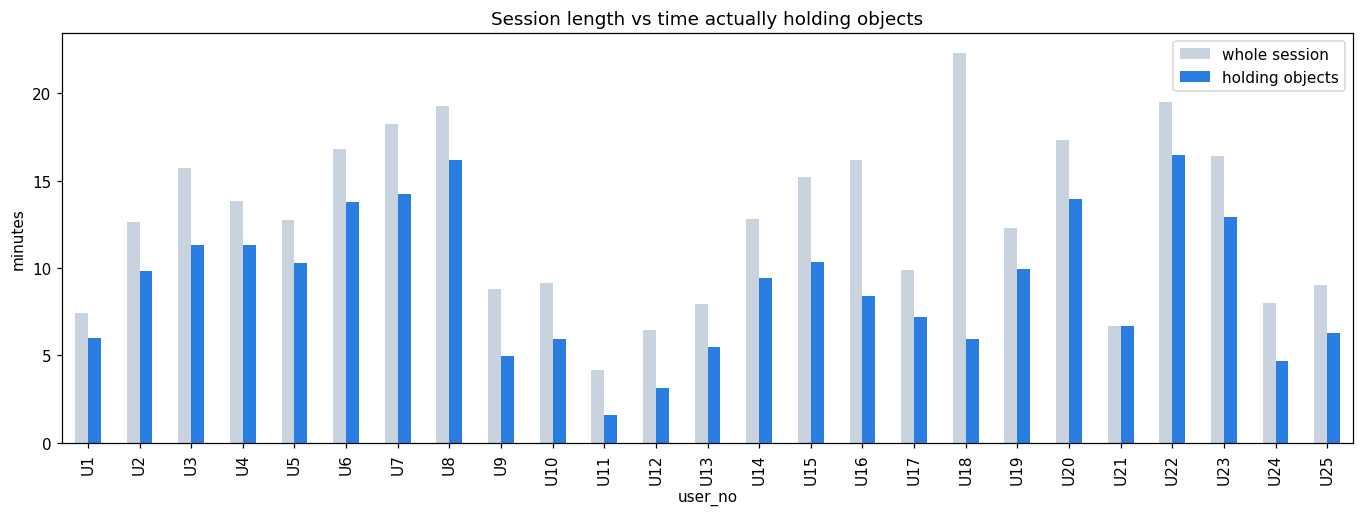

In [ ]:
obj_cols = [c for c in per_user.columns if c in set(items.item_name)]
ax = (per_user[obj_cols] / 60).plot(kind="bar", stacked=True, figsize=(max(10, len(per_user) * 0.5), 5.2),
                                    color=COLORS[:len(obj_cols)])
ax.set_ylabel("minutes holding"); ax.set_title("Time each visitor held each object")
plt.tight_layout(); plt.show()

ax = pd.DataFrame({"whole session": per_user["session (s)"] / 60,
                   "holding objects": per_user["TOTAL holding (s)"] / 60}).plot(
    kind="bar", figsize=(max(10, len(per_user) * 0.5), 4.8), color=["#c9d3df", "#2a7de1"])
ax.set_ylabel("minutes"); ax.set_title("Session length vs time actually holding objects")
plt.tight_layout(); plt.show()

## 7. First object touched
Which object does a visitor pick up first? (Table = counts and share of visitors.)

,visitors,%
item_name,,
Nike Figurine,9,36.0
Hidden artifact 1,8,32.0
Kohl Vessel,6,24.0
Hidden artifact 2,2,8.0


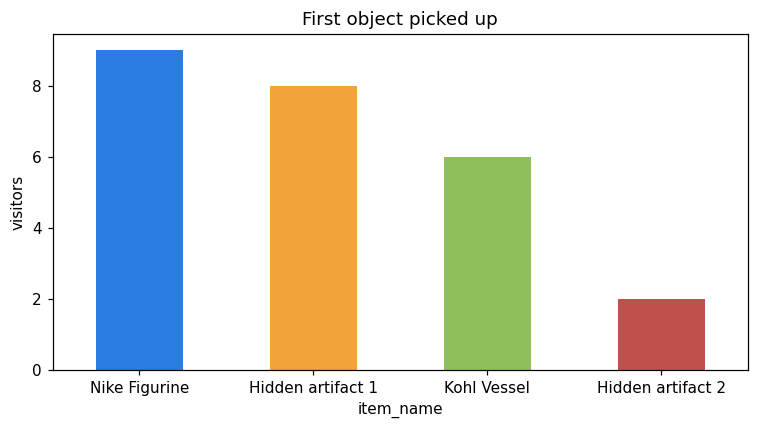

In [ ]:
first = holds.sort_values("start").groupby("user_no").first()
t = first.item_name.value_counts().rename("visitors").to_frame()
t["%"] = (100 * t.visitors / len(first)).round(1)
display(t)
ax = t.visitors.plot(kind="bar", color=COLORS[:len(t)], figsize=(7, 4)); ax.set_ylabel("visitors")
ax.set_title("First object picked up"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 8. Questions asked
**Table:** number of questions per object and per visitor.
**Graphs:** questions per visitor (stacked by the object that was held), and - does a visitor who holds the AI objects longer also ask more questions? (scatter, with the correlation).

In [ ]:
q_obj = utts.groupby("item_name").size().rename("questions").to_frame()
q_obj["% of questions"] = (100 * q_obj.questions / q_obj.questions.sum()).round(1)
display(q_obj)

q_user = utts.pivot_table(index="user_no", columns="item_name", values="user_text",
                          aggfunc="count", fill_value=0).reindex(persons.user_no).fillna(0).astype(int)
q_user["TOTAL"] = q_user.sum(axis=1)
q_user.index = "U" + q_user.index.astype(str)
display(q_user.describe().loc[["count", "mean", "50%", "max"]].round(1).rename(index={"50%": "median"}))

,questions,% of questions
item_name,,
Kohl Vessel,52,47.3
Nike Figurine,52,47.3
none,6,5.5


item_name,Kohl Vessel,Nike Figurine,none,TOTAL
count,25.0,25.0,25.0,25.0
mean,2.1,2.1,0.2,4.4
median,2.0,2.0,0.0,4.0
max,7.0,5.0,2.0,10.0


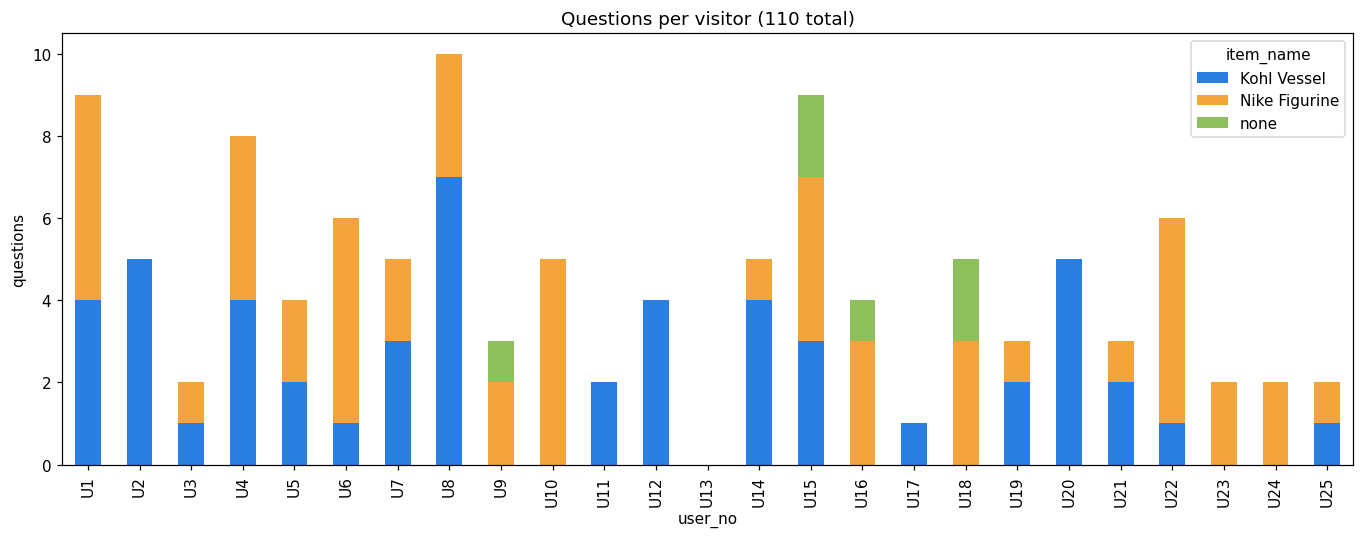

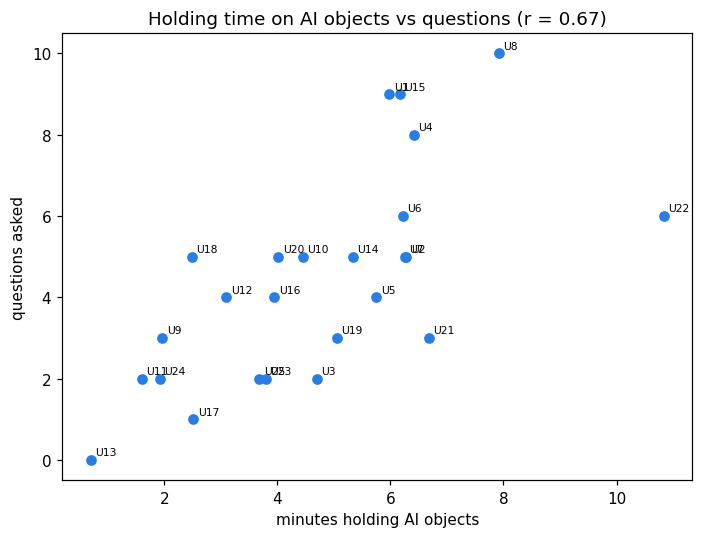

In [ ]:
ax = q_user.drop(columns="TOTAL").plot(kind="bar", stacked=True, figsize=(max(10, len(q_user) * 0.5), 5), color=COLORS)
ax.set_ylabel("questions"); ax.set_title(f"Questions per visitor ({len(utts)} total)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(persons.hold_ai_items_sec / 60, persons.n_questions, color=AI_COLOR)
for _, r in persons.iterrows():
    ax.annotate(f"U{r.user_no}", (r.hold_ai_items_sec / 60, r.n_questions), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("minutes holding AI objects"); ax.set_ylabel("questions asked")
corr = persons[["hold_ai_items_sec", "n_questions"]].corr().iloc[0, 1]
ax.set_title(f"Holding time on AI objects vs questions (r = {corr:.2f})")
plt.tight_layout(); plt.show()

## 9. AI latency (pipeline timing)
Only the **recordings that logged `pipeline` lines** have timings; the earlier ones did not. First: which visitors have timing.

The pipeline for every question is: **STT** (speech -> text) -> **GPT** (answer) -> **language detection** -> **TTS** (text -> speech). `total` is the full pipeline.
*Note: the total starts when the audio arrives at the server and ends when the TTS audio is ready - upload time and audio playback are not included.*

In [ ]:
cov = persons[["user_no", "folder", "date", "n_questions", "n_timed_questions", "timing_measured"]].copy()
cov.user_no = "U" + cov.user_no.astype(str)
display(cov.set_index("user_no"))
print(f"{int(persons.timing_measured.sum())} of {len(persons)} visitors have timing; {int(persons.n_timed_questions.sum())} timed questions out of {len(utts)}.")

,folder,date,n_questions,n_timed_questions,timing_measured
user_no,,,,,
U1,NO_CLOCK,2026-05-06,9,0,False
U2,NO_CLOCK,2026-06-23,5,0,False
U3,NO_CLOCK,2026-06-23,2,0,False
U4,NO_CLOCK,2026-06-23,8,0,False
U5,NO_CLOCK,2026-07-04,4,0,False
U6,NO_CLOCK,2026-07-07,6,0,False
U7,NO_CLOCK,2026-07-07,5,0,False
U8,NO_CLOCK,2026-07-07,10,0,False
U9,CLOCK,2026-08-01,3,3,True


16 of 25 visitors have timing; 60 timed questions out of 110.


**Table:** latency per pipeline stage (seconds) - average, median, 90th percentile (p90: 9 of 10 questions were faster than this), min, max.

In [ ]:
display(latency.set_index("stage"))

,n,avg_sec,median_sec,p90_sec,min_sec,max_sec
stage,,,,,,
STT (speech to text),60,3.26,3.07,4.97,0.870,9.369
GPT answer,60,1.66,1.51,2.33,0.858,4.256
language detect,60,0.98,0.98,1.31,0.537,1.722
TTS (text to speech),60,2.79,2.51,4.55,1.036,7.486
TOTAL pipeline,60,8.96,8.43,12.39,4.857,21.467


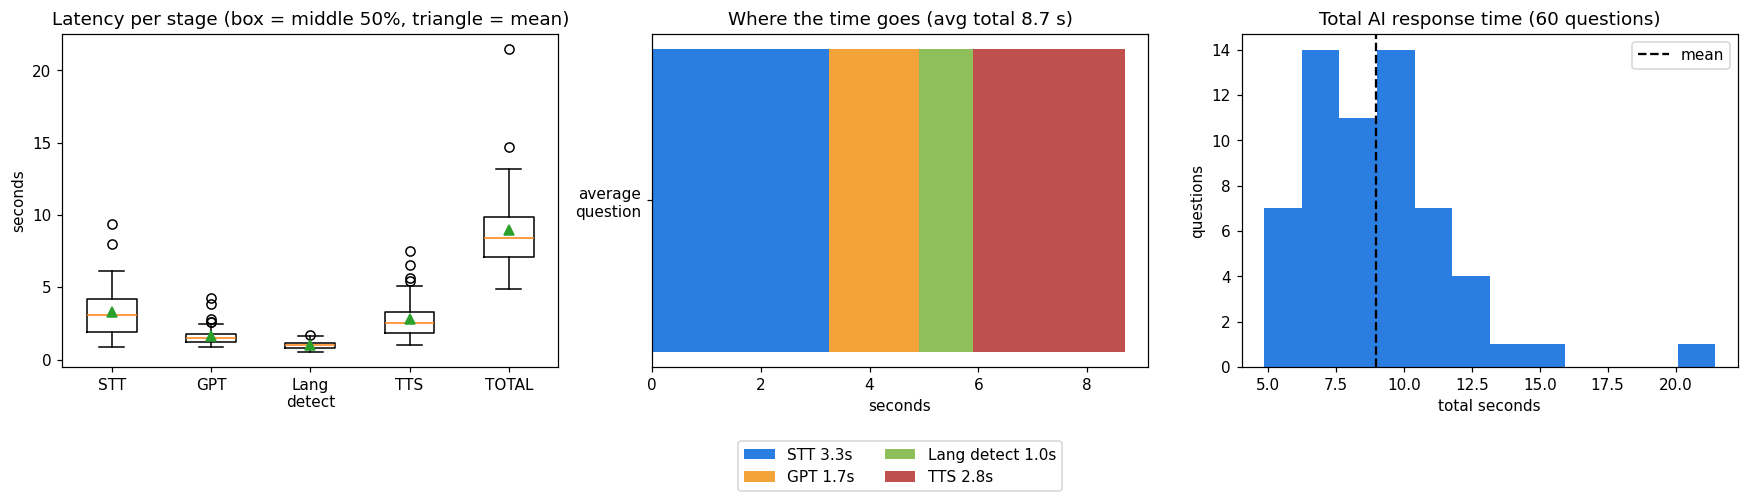

In [ ]:
timed = utts[utts.total_sec.notna()].copy()
stages = [("stt_sec", "STT"), ("gpt_sec", "GPT"), ("lang_sec", "Lang\ndetect"), ("tts_sec", "TTS"), ("total_sec", "TOTAL")]

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
ax[0].boxplot([timed[k].dropna() for k, _ in stages], tick_labels=[l for _, l in stages], showmeans=True)
ax[0].set_ylabel("seconds"); ax[0].set_title("Latency per stage (box = middle 50%, triangle = mean)")

left = 0
for i, (k, l) in enumerate(stages[:4]):
    m = timed[k].mean()
    ax[1].barh(["average\nquestion"], [m], left=left, color=COLORS[i], label=f"{l.replace(chr(10), ' ')} {m:.1f}s")
    left += m
ax[1].set_xlabel("seconds"); ax[1].set_title(f"Where the time goes (avg total {left:.1f} s)")
ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)

ax[2].hist(timed.total_sec, bins=12, color=AI_COLOR)
ax[2].axvline(timed.total_sec.mean(), color="black", linestyle="--", label="mean")
ax[2].set_xlabel("total seconds"); ax[2].set_ylabel("questions"); ax[2].legend()
ax[2].set_title(f"Total AI response time ({len(timed)} questions)")
plt.tight_layout(); plt.show()

### Does a longer answer take longer? / does latency change between recording days?
**Table + graph 1:** average timing per recording day (useful if you changed something in the pipeline between days).
**Graph 2:** characters in the AI answer vs total time (the TTS step grows with the length of the answer).

,stt_sec,gpt_sec,lang_sec,tts_sec,total_sec,questions
ts,,,,,,
2026-08-01,3.48,1.51,0.91,2.70,8.83,19
2026-09-09,1.64,1.30,0.87,2.94,7.03,9
2026-09-22,2.41,1.73,1.11,2.90,8.57,4
2026-10-17,3.44,1.82,0.98,3.33,9.85,16
2026-10-31,4.16,1.92,1.14,2.07,9.57,12


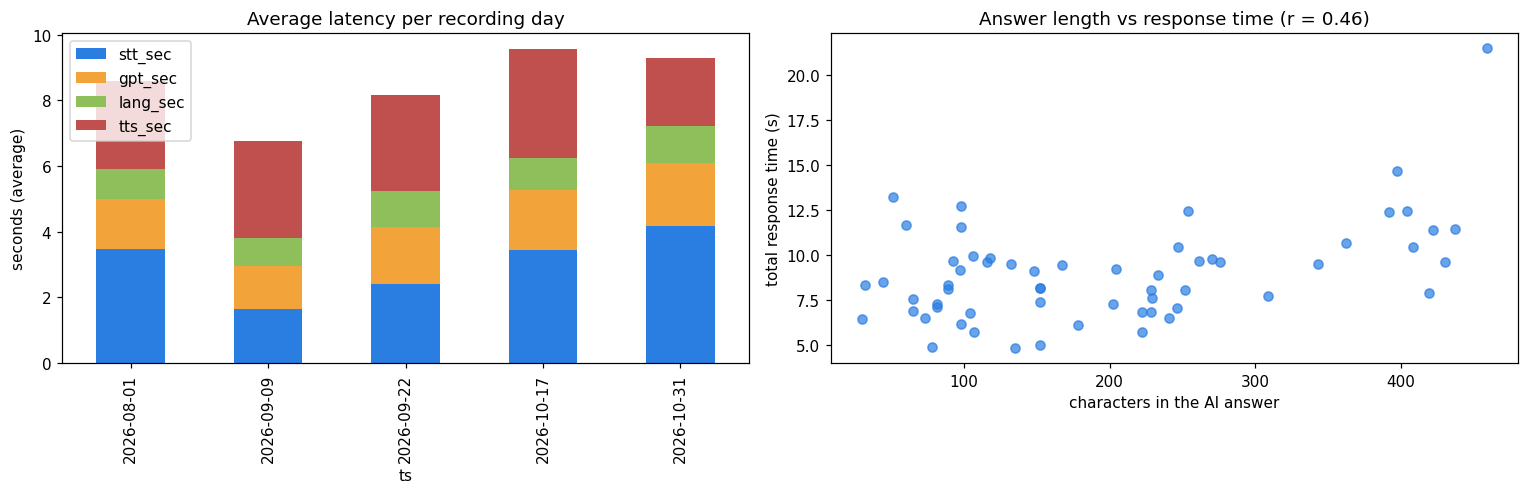

In [ ]:
by_day = timed.groupby(timed.ts.dt.date)[["stt_sec", "gpt_sec", "lang_sec", "tts_sec", "total_sec"]].agg("mean").round(2)
by_day["questions"] = timed.groupby(timed.ts.dt.date).size()
display(by_day)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
by_day[["stt_sec", "gpt_sec", "lang_sec", "tts_sec"]].plot(kind="bar", stacked=True, ax=ax[0], color=COLORS[:4])
ax[0].set_ylabel("seconds (average)"); ax[0].set_title("Average latency per recording day")
ax[1].scatter(timed.assistant_text.str.len(), timed.total_sec, color=AI_COLOR, alpha=0.7)
ax[1].set_xlabel("characters in the AI answer"); ax[1].set_ylabel("total response time (s)")
r = np.corrcoef(timed.assistant_text.str.len(), timed.total_sec)[0, 1]
ax[1].set_title(f"Answer length vs response time (r = {r:.2f})")
plt.tight_layout(); plt.show()

## 10. Languages
The language is taken from the writing system of the transcribed question (Arabic / Hebrew / English-Latin / other). **Table:** questions per language and the main language of each visitor. **Graph:** questions per language.

,questions,%
script,,
Arabic,86,78.2
Latin,19,17.3
Korean,2,1.8
Other,1,0.9
CJK,1,0.9
Hebrew,1,0.9


,visitors
main_language,
Arabic,21
Latin,3
None,1


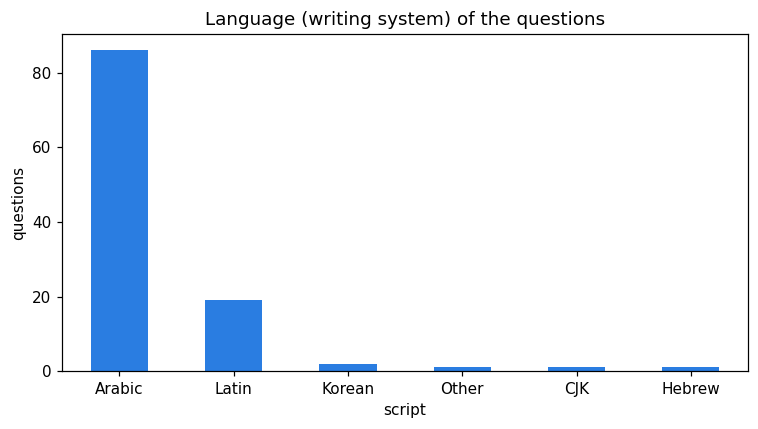

In [ ]:
lang = utts.script.value_counts().rename("questions").to_frame()
lang["%"] = (100 * lang.questions / lang.questions.sum()).round(1)
display(lang)
display(persons.main_language.value_counts(dropna=False).rename("visitors").to_frame())
ax = lang.questions.plot(kind="bar", color=AI_COLOR, figsize=(7, 4)); ax.set_ylabel("questions")
ax.set_title("Language (writing system) of the questions"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 11. Every question & answer per visitor - with timings
One block per visitor (U1, U2, ...), in the order of the recordings. Each block shows, for every question: the object that was held, the **question** (as transcribed), the AI **answer**, and the timings in seconds: `stt` (speech->text), `gpt`, `lang`, `tts`, and `total`.
Empty timing cells = that recording did not log the pipeline timing.

First the **single long table** with all questions (you can filter / sort it), then the per-visitor blocks.

In [ ]:
qa = utts.copy()
qa["date"] = qa.ts.dt.strftime("%Y-%m-%d")
qa["time"] = qa.ts.dt.strftime("%H:%M:%S")
qa["q_no"] = qa.groupby("user_no").cumcount() + 1
qa = qa.rename(columns={"user_text": "question", "assistant_text": "answer"})
qa_cols = ["user_no", "person", "date", "time", "q_no", "item_name", "question", "answer",
           "stt_sec", "gpt_sec", "lang_sec", "tts_sec", "total_sec", "detected_lang"]
qa = qa[qa_cols]

# text-friendly display: wrap long text, Arabic/Hebrew read right-to-left automatically
TEXT_STYLE = {"white-space": "pre-wrap", "text-align": "start", "unicode-bidi": "plaintext", "min-width": "260px", "max-width": "520px"}
def show_table(df):
    display(df.style.hide(axis="index").set_properties(subset=["question", "answer"], **TEXT_STYLE)
              .format({c: "{:.2f}" for c in ["stt_sec", "gpt_sec", "lang_sec", "tts_sec", "total_sec"]}, na_rep=""))

print(f"{len(qa)} questions from {qa.user_no.nunique()} visitors")
show_table(qa)

110 questions from 24 visitors


user_no,person,date,time,q_no,item_name,question,answer,stt_sec,gpt_sec,lang_sec,tts_sec,total_sec,detected_lang
1,NO_CLOCK/interaction_log (3)#s1,2026-05-06,16:19:05,1,Nike Figurine,شو تاريخها من أي سنين هاي,تمثال نايكي الذي تحمله يعود إلى الفترة الرومانية، من 63 قبل الميلاد حتى 320 ميلادي. نايكي كانت تُعتبر إلهة النصر في الأساطير اليونانية والرومانية.,,,,,,
1,NO_CLOCK/interaction_log (3)#s1,2026-05-06,16:19:40,2,Nike Figurine,شو واحدة من الأساطير المعروفة عنها؟,من الأساطير المعروفة عن نايكي أنها كانت تُعتبر الحامية للنصر في المعارك. كانت تُصوَّر بجانب زيوس في أولمبيا، حيث كانت تمنح النصر للآلهة وللبشر. يظهر تمثالها في الفنون القديمة كمثال على القوة والدعم الإلهي في الانتصارات.,,,,,,
1,NO_CLOCK/interaction_log (3)#s1,2026-05-06,16:20:15,3,Nike Figurine,اشتركوا في القناة,أنا هنا لمساعدتك في استكشاف المعلومات حول المعروضات. إذا كان لديك أي أسئلة عن تمثال نايكي أو أي شيء آخر في المتحف، فلا تتردد في طرحها!,,,,,,
1,NO_CLOCK/interaction_log (3)#s1,2026-05-06,16:20:41,4,Nike Figurine,من أي مادي معمول التمثال في المتحف؟,"التمثال مصنوع من الطين، وهو ما يُعرف بالـ ""تيراكوتا"". هذه المادة كانت شائعة في صناعة التماثيل خلال العصور القديمة.",,,,,,
1,NO_CLOCK/interaction_log (3)#s1,2026-05-06,16:21:07,5,Nike Figurine,آخر سؤال هل اسم شركة نايكي هي نفس الاسم؟,نعم، اسم شركة نايكي مستمد من اسم الإلهة اليونانية نايكي، إلهة النصر. تعكس الشركة روح الانتصار والنجاح في الرياضة، تماماً كما كانت تُعتبر نايكي رمزاً للنصر في الأساطير القديمة.,,,,,,
1,NO_CLOCK/interaction_log (3)#s1,2026-05-06,16:22:28,6,Kohl Vessel,شو الهدف من هذا؟,هذا وعاء كحل، مصنوع من الزجاج بشكل جميل. يُستخدم لتخزين الكحل، وهو مستحضر تجميل. يعكس هذا الوعاء أهمية ممارسات الجمال ومكانة النساء في المجتمع البيزنطي.,,,,,,
1,NO_CLOCK/interaction_log (3)#s1,2026-05-06,16:22:55,7,Kohl Vessel,طرف الإناء يوجد فتحة مكسورة,نعم، يبدو أن بعض أجزاء الزخرفة مفقودة. رغم ذلك، يظل التصميم الدقيق للوعاء يدل على القيمة العالية للمحتويات التي كان يحملها. كانت هذه الأوعية تعكس مكانة النساء وأهمية الجمال في ذلك الوقت.,,,,,,
1,NO_CLOCK/interaction_log (3)#s1,2026-05-06,16:23:25,8,Kohl Vessel,ونرى ماذا يفعل الكحول,الكحل هو مستحضر تجميل يستخدم لتحديد العيون وزيادة جمالها. كان له أيضًا دور ثقافي واجتماعي في مجتمعات متعددة، بما في ذلك المجتمع البيزنطي. استخدمته النساء بشكل شائع كجزء من روتين جمالهن.,,,,,,
1,NO_CLOCK/interaction_log (3)#s1,2026-05-06,16:23:58,9,Kohl Vessel,من مراتر؟ من شو بحضروه، من شو بين عمل الكحول,"لم أتمكن من العثور على معلومات حول ""مراتر"" أو ما يقصد به. لكن يمكنني أن أخبرك أن الكحل عادة ما يُصنع من مكونات طبيعية مثل الفحم أو المعادن، ويستخدم في تحديد العيون. إذا كنت ترغب في معرفة المزيد عن موضوع آخر، فلا تتردد في سؤالي.",,,,,,
2,NO_CLOCK/interaction_log (6)#s1,2026-06-23,13:32:04,1,Kohl Vessel,من ماذا صنع هذا الدولة؟,هذا الوعاء مصنوع من الزجاج. إنه وعاء مزخرف بشكل دقيق، حيث يتكون من أنبوبين متصلين معًا، ومُلفوف بخيط زجاجي يشكل نمطًا متموجًا.,,,,,,


In [ ]:
# one block per visitor
for _, p in persons.iterrows():
    u = qa[qa.user_no == p.user_no]
    held = ", ".join(sorted({n for n in holds[holds.user_no == p.user_no].item_name}))
    head = (f"### U{p.user_no} &nbsp;-&nbsp; {p.date:%Y-%m-%d} {p.start_time} &nbsp;-&nbsp; `{p.person}`\n\n"
            f"questions: **{len(u)}** &nbsp;|&nbsp; objects held: {held or '-'} &nbsp;|&nbsp; "
            f"session: {p.session_sec / 60:.1f} min &nbsp;|&nbsp; holding: {p.hold_total_sec / 60:.1f} min")
    if u.total_sec.notna().any():
        head += f" &nbsp;|&nbsp; avg AI response: **{u.total_sec.mean():.1f} s**"
    display(Markdown(head))
    if len(u):
        show_table(u.drop(columns=["user_no", "person", "date", "detected_lang"]))
    else:
        display(Markdown("*(picked up objects, asked nothing)*"))

### U1 &nbsp;-&nbsp; 2026-05-06 16:16:33 &nbsp;-&nbsp; `NO_CLOCK/interaction_log (3)#s1`

questions: **9** &nbsp;|&nbsp; objects held: Kohl Vessel, Nike Figurine &nbsp;|&nbsp; session: 7.4 min &nbsp;|&nbsp; holding: 6.0 min

time,q_no,item_name,question,answer,stt_sec,gpt_sec,lang_sec,tts_sec,total_sec
16:19:05,1,Nike Figurine,شو تاريخها من أي سنين هاي,تمثال نايكي الذي تحمله يعود إلى الفترة الرومانية، من 63 قبل الميلاد حتى 320 ميلادي. نايكي كانت تُعتبر إلهة النصر في الأساطير اليونانية والرومانية.,,,,,
16:19:40,2,Nike Figurine,شو واحدة من الأساطير المعروفة عنها؟,من الأساطير المعروفة عن نايكي أنها كانت تُعتبر الحامية للنصر في المعارك. كانت تُصوَّر بجانب زيوس في أولمبيا، حيث كانت تمنح النصر للآلهة وللبشر. يظهر تمثالها في الفنون القديمة كمثال على القوة والدعم الإلهي في الانتصارات.,,,,,
16:20:15,3,Nike Figurine,اشتركوا في القناة,أنا هنا لمساعدتك في استكشاف المعلومات حول المعروضات. إذا كان لديك أي أسئلة عن تمثال نايكي أو أي شيء آخر في المتحف، فلا تتردد في طرحها!,,,,,
16:20:41,4,Nike Figurine,من أي مادي معمول التمثال في المتحف؟,"التمثال مصنوع من الطين، وهو ما يُعرف بالـ ""تيراكوتا"". هذه المادة كانت شائعة في صناعة التماثيل خلال العصور القديمة.",,,,,
16:21:07,5,Nike Figurine,آخر سؤال هل اسم شركة نايكي هي نفس الاسم؟,نعم، اسم شركة نايكي مستمد من اسم الإلهة اليونانية نايكي، إلهة النصر. تعكس الشركة روح الانتصار والنجاح في الرياضة، تماماً كما كانت تُعتبر نايكي رمزاً للنصر في الأساطير القديمة.,,,,,
16:22:28,6,Kohl Vessel,شو الهدف من هذا؟,هذا وعاء كحل، مصنوع من الزجاج بشكل جميل. يُستخدم لتخزين الكحل، وهو مستحضر تجميل. يعكس هذا الوعاء أهمية ممارسات الجمال ومكانة النساء في المجتمع البيزنطي.,,,,,
16:22:55,7,Kohl Vessel,طرف الإناء يوجد فتحة مكسورة,نعم، يبدو أن بعض أجزاء الزخرفة مفقودة. رغم ذلك، يظل التصميم الدقيق للوعاء يدل على القيمة العالية للمحتويات التي كان يحملها. كانت هذه الأوعية تعكس مكانة النساء وأهمية الجمال في ذلك الوقت.,,,,,
16:23:25,8,Kohl Vessel,ونرى ماذا يفعل الكحول,الكحل هو مستحضر تجميل يستخدم لتحديد العيون وزيادة جمالها. كان له أيضًا دور ثقافي واجتماعي في مجتمعات متعددة، بما في ذلك المجتمع البيزنطي. استخدمته النساء بشكل شائع كجزء من روتين جمالهن.,,,,,
16:23:58,9,Kohl Vessel,من مراتر؟ من شو بحضروه، من شو بين عمل الكحول,"لم أتمكن من العثور على معلومات حول ""مراتر"" أو ما يقصد به. لكن يمكنني أن أخبرك أن الكحل عادة ما يُصنع من مكونات طبيعية مثل الفحم أو المعادن، ويستخدم في تحديد العيون. إذا كنت ترغب في معرفة المزيد عن موضوع آخر، فلا تتردد في سؤالي.",,,,,


### U2 &nbsp;-&nbsp; 2026-06-23 13:27:59 &nbsp;-&nbsp; `NO_CLOCK/interaction_log (6)#s1`

questions: **5** &nbsp;|&nbsp; objects held: Hidden artifact 1, Kohl Vessel, Nike Figurine &nbsp;|&nbsp; session: 12.7 min &nbsp;|&nbsp; holding: 9.8 min

time,q_no,item_name,question,answer,stt_sec,gpt_sec,lang_sec,tts_sec,total_sec
13:32:04,1,Kohl Vessel,من ماذا صنع هذا الدولة؟,هذا الوعاء مصنوع من الزجاج. إنه وعاء مزخرف بشكل دقيق، حيث يتكون من أنبوبين متصلين معًا، ومُلفوف بخيط زجاجي يشكل نمطًا متموجًا.,,,,,
13:38:57,2,Kohl Vessel,맛있어서..,"I'm sorry, but I don't understand that language. Please ask your question in Hebrew, Arabic, or English.",,,,,
13:39:22,3,Kohl Vessel,هل ينجد نوع آخر من هذا الكحار؟ أم هو نوع واحد؟,لا أملك معلومات كافية عن أنواع أخرى من الكحل، لكن الكحل هو مستحضر تجميلي يستخدم في العديد من الثقافات. قد تختلف أنواعه ومكوناته حسب المنطقة والتقاليد.,,,,,
13:39:51,4,Kohl Vessel,That's right,"I'm glad you agree! If you have any more questions about the kohl vessel or anything else, feel free to ask.",,,,,
13:40:11,5,Kohl Vessel,هل يتم استعمال إناء الكحل اليوم؟,نعم، إناء الكحل لا يزال يُستخدم اليوم في بعض الثقافات. يُعتبر الكحل جزءًا من تقاليد الجمال في العديد من الدول، خاصة في الشرق الأوسط. يُستخدم لتحديد العينين وإبراز جمالها.,,,,,


### U3 &nbsp;-&nbsp; 2026-06-23 14:02:12 &nbsp;-&nbsp; `NO_CLOCK/interaction_log (4)#s1`

questions: **2** &nbsp;|&nbsp; objects held: Hidden artifact 1, Hidden artifact 2, Kohl Vessel, Nike Figurine &nbsp;|&nbsp; session: 15.7 min &nbsp;|&nbsp; holding: 11.3 min

time,q_no,item_name,question,answer,stt_sec,gpt_sec,lang_sec,tts_sec,total_sec
14:11:46,1,Nike Figurine,نضغط على الضغط نضغط على الضغط نضغط على الضغط,أنا لا أستطيع التعرف على شيء الآن. يرجى وضعه جانبًا والانتقال إلى العنصر التالي لإعادة تشغيل المحادثة، يمكننا العودة إليه لاحقًا.,,,,,
14:17:05,2,Kohl Vessel,Can you give me extra information about this object?,"You are holding a finely crafted glass vessel used to store kohl, a cosmetic. It consists of two tubes joined together, wrapped with a glass thread that forms a wavy decorative pattern. Although parts of the decoration are missing, the delicate craftsmanship highlights the high value of its contents. This vessel was often paired with a thin metal stick to extract oils and pigments from within. It reflects the importance of beauty practices and women’s status in Byzantine society. If you have more specific questions, feel free to ask!",,,,,


... (40 outputs left out)

### U24 &nbsp;-&nbsp; 2026-10-31 10:41:15 &nbsp;-&nbsp; `CLOCK/interaction_log (19)#s1`

questions: **2** &nbsp;|&nbsp; objects held: Hidden artifact 2, Nike Figurine &nbsp;|&nbsp; session: 8.0 min &nbsp;|&nbsp; holding: 4.7 min &nbsp;|&nbsp; avg AI response: **7.0 s**

time,q_no,item_name,question,answer,stt_sec,gpt_sec,lang_sec,tts_sec,total_sec
10:48:17,1,Nike Figurine,You,I’m not detecting an item right now. Please place it down and move on to the next item for now to reboot the conversation; we can come back to it later.,3.02,1.74,1.24,1.26,7.41
10:48:55,2,Nike Figurine,من أي فترة هذا التمثال؟,هذا التمثال يعود إلى الفترة الرومانية، من 63 قبل الميلاد إلى 320 ميلادية.,2.82,1.41,1.12,1.04,6.50


### U25 &nbsp;-&nbsp; 2026-10-31 11:16:49 &nbsp;-&nbsp; `CLOCK/interaction_log (20)#s1`

questions: **2** &nbsp;|&nbsp; objects held: Hidden artifact 1, Kohl Vessel, Nike Figurine &nbsp;|&nbsp; session: 9.0 min &nbsp;|&nbsp; holding: 6.3 min &nbsp;|&nbsp; avg AI response: **9.7 s**

time,q_no,item_name,question,answer,stt_sec,gpt_sec,lang_sec,tts_sec,total_sec
11:23:16,1,Kohl Vessel,لا يوجد ثقوب يضع في داخل السائل الكحول لكن لا أرى غطاء للإناء لماذا لا يجف دون غطاء,الإناء الذي تحمله هو وعاء الكحل، وهو مصنوع من الزجاج لتخزين مستحضرات التجميل. عادةً، يُستخدم مع عصا معدنية رفيعة لاستخراج الزيوت والأصباغ. بالنسبة لعدم وجود غطاء، فإن تصميمه يعتمد على أن الكحل يُستخدم بشكل متكرر، مما يقلل من الحاجة لغطاء دائم.,3.81,2.16,1.33,2.98,10.43
11:25:21,2,Nike Figurine,قولوا ميكي هذه في حال هي إلهة رومانية ليس بصرية من كان إلهة لأي دولة كانت,ميكي، أو فيكتوريا كما تُعرف في التقليد الروماني، هي إلهة النصر. كانت تُعبد في روما، وقد ارتبطت بالنصر العسكري والنجاح. كانت تمثل الدعم الإلهي للانتصارات، سواء للآلهة أو للبشر. في الثقافة اليونانية، كانت تُعرف باسم نايك، إلهة النصر.,3.88,1.53,1.13,2.26,8.90


## 12. Export
Saves the tables to the `analysis_out` folder:
- `notebook_tables.xlsx` - sheets: overall, items, per_visitor, holds, latency, qa_all, audit
- `qa_per_visitor_with_timings.xlsx` - sheet `ALL` + **one sheet per visitor** (questions, answers and all timings)
- `qa_all_with_timings.csv` - the same long table as CSV

In [ ]:
OUT = ROOT / "analysis_out"; OUT.mkdir(exist_ok=True)
qa.to_csv(OUT / "qa_all_with_timings.csv", index=False, encoding="utf-8-sig")

try:
    from openpyxl.styles import Alignment, Font

    def style_sheet(ws, widths):
        for c in ws[1]:
            c.font = Font(bold=True)
        for col, w in widths.items():
            ws.column_dimensions[col].width = w
        for row in ws.iter_rows(min_row=2):
            for c in row:
                c.alignment = Alignment(wrap_text=True, vertical="top")
        ws.freeze_panes = "A2"

    widths = {"A": 8, "B": 30, "C": 11, "D": 9, "E": 6, "F": 18, "G": 60, "H": 80,
              "I": 9, "J": 9, "K": 9, "L": 9, "M": 9, "N": 8}
    with pd.ExcelWriter(OUT / "qa_per_visitor_with_timings.xlsx", engine="openpyxl") as xw:
        qa.to_excel(xw, sheet_name="ALL", index=False); style_sheet(xw.sheets["ALL"], widths)
        used = {"ALL"}
        for _, p in persons.iterrows():
            u = qa[qa.user_no == p.user_no]
            if u.empty:
                continue
            name = f"U{p.user_no:02d} {p.person}".translate({ord(c): None for c in '\\/*?:[]'})[:31]
            k = 1
            while name in used:
                k += 1; name = name[:28] + f"_{k}"
            used.add(name)
            u.to_excel(xw, sheet_name=name, index=False); style_sheet(xw.sheets[name], widths)

    with pd.ExcelWriter(OUT / "notebook_tables.xlsx", engine="openpyxl") as xw:
        overall.T.rename(columns={0: "value"}).to_excel(xw, sheet_name="overall")
        items.to_excel(xw, sheet_name="items", index=False)
        per_user.to_excel(xw, sheet_name="per_visitor")
        holds_all.to_excel(xw, sheet_name="holds", index=False)
        latency.to_excel(xw, sheet_name="latency", index=False)
        qa.to_excel(xw, sheet_name="qa_all", index=False)
        audit_df.to_excel(xw, sheet_name="audit", index=False)
    print("Saved Excel files + CSV in", OUT)
except ImportError:
    print("Excel export skipped (run: pip install openpyxl). The CSV was saved in", OUT)

Saved Excel files + CSV in /content/drive/MyDrive/ניתוח דאטא מפגשים/JSON/analysis_out
